# LoomIQ 05 · Fabric Defect Detection

Train a model that finds defects in fabric images, and turn its output into a **DHU** quality score.

Reusable code: `src/loomiq/vision/` (`prepare_dataset.py`, `train_defect.py`, `detect.py`).

> **Needs the AITEX dataset** in `data/images/aitex/` (see `docs/DATASETS.md`). The first cell checks for it.

## Goals

1. Look at the AITEX images and their defect masks
2. Turn them into a training set: tiles, boxes, and a split **by source image**
3. Fine-tune a pretrained YOLOv8 nano model (transfer learning)
4. Evaluate on test images at two levels: tiles (YOLO metrics) and whole panels (what a factory needs)
5. Check how accurate the DHU estimate is, and look at the mistakes

In [1]:
# Setup
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from loomiq.config import get_path
from loomiq.utils.plotting import apply_style, save_figure
from loomiq.vision import detect, prepare_dataset as prep
from loomiq.vision.train_defect import train_defect_model

apply_style()
settings = prep.get_settings()
raw_dir = settings["raw_dir"]
assert (raw_dir / "Defect_images").exists(), (
    f"AITEX not found in {raw_dir}. Download it first (see docs/DATASETS.md)."
)

## 1. The images

In [2]:
sources = prep.find_aitex_images(raw_dir)
defect_sources = [s for s in sources if s.has_defect]
print(f"{len(defect_sources)} defect images, {len(sources) - len(defect_sources)} defect-free images")

first = prep.load_gray(defect_sources[0].path)
print("Image size (height x width):", first.shape)

2026-11-06 20:12:30 | WARNING  | loomiq.vision.prepare_dataset | No mask for 0100_025_08.png; skipped


2026-11-06 20:12:30 | INFO     | loomiq.vision.prepare_dataset | Found 105 defect images and 141 defect-free images


105 defect images, 141 defect-free images
Image size (height x width): (256, 4096)


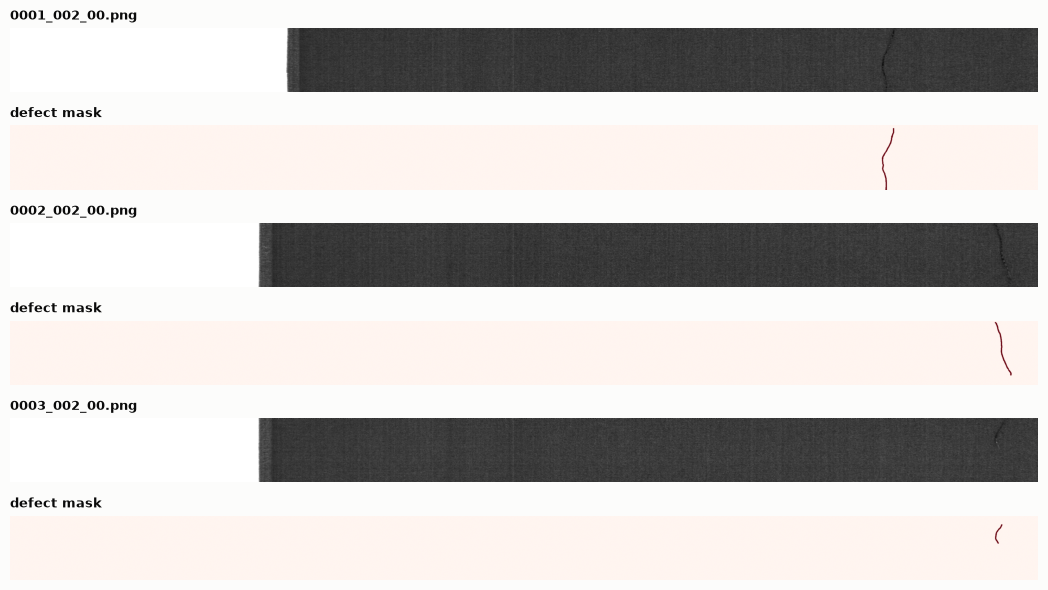

In [3]:
fig, axes = plt.subplots(6, 1, figsize=(14, 6))
for ax, source in zip(axes[::2], defect_sources[:3]):
    ax.imshow(prep.load_gray(source.path), cmap="gray"); ax.set_title(source.path.name, fontsize=9); ax.axis("off")
for ax, source in zip(axes[1::2], defect_sources[:3]):
    image = prep.load_gray(source.path)
    ax.imshow(prep.combined_mask(source, image.shape), cmap="Reds"); ax.set_title("defect mask", fontsize=9); ax.axis("off")
plt.tight_layout()
save_figure(fig, "vision_01_examples")
plt.show()

**What we see:** long, thin strips (4096 × 256) where defects are tiny: a few pixels wide and often only slightly darker or lighter than the weave. The **mask** marks exactly which pixels are defective; we turn each blob into a box for YOLO.

In [4]:
sizes = []
for source in defect_sources:
    image = prep.load_gray(source.path)
    for x1, y1, x2, y2 in prep.mask_to_boxes(prep.combined_mask(source, image.shape), settings["min_defect_area"]):
        sizes.append({"width": x2 - x1, "height": y2 - y1})
sizes = pd.DataFrame(sizes)
print(f"{len(sizes)} defects in {len(defect_sources)} images")
sizes.describe().round(0)

169 defects in 105 images


,width,height
count,169.0,169.0
mean,124.0,38.0
std,499.0,61.0
min,1.0,2.0
25%,4.0,6.0
50%,7.0,10.0
75%,14.0,34.0
max,3607.0,255.0


## 2. Build the training set

- **Tiles:** each strip is cut into 256 × 256 squares, a size YOLO handles well.
- **Split by source image:** all tiles from one photo go to the same split (train, val or test). Splitting tiles randomly would put neighbouring pieces of the same defect in train and test, inflating the scores.
- **Background tiles:** defect-free tiles far outnumber defect tiles, so training keeps about one clean tile per defect tile.

In [5]:
data_yaml = prep.prepare_fabric_dataset()
manifest = pd.read_csv(settings["prepared_dir"] / "manifest.csv")
manifest.groupby("split").agg(images=("source", "size"), defective=("has_defect", "sum"), defects=("true_defects", "sum"))

2026-11-06 20:12:36 | WARNING  | loomiq.vision.prepare_dataset | No mask for 0100_025_08.png; skipped


2026-11-06 20:12:36 | INFO     | loomiq.vision.prepare_dataset | Found 105 defect images and 141 defect-free images


2026-11-06 20:12:39 | WARNING  | loomiq.vision.prepare_dataset | Mask of 0106_010_03.png has no usable defect pixels; skipped


2026-11-06 20:12:48 | INFO     | loomiq.vision.prepare_dataset | train: 173 source images -> 145 defect tiles + 145 defect-free tiles


2026-11-06 20:12:50 | INFO     | loomiq.vision.prepare_dataset | val  : 37 source images -> 17 defect tiles + 17 defect-free tiles


2026-11-06 20:12:52 | INFO     | loomiq.vision.prepare_dataset | test : 36 source images -> 22 defect tiles + 22 defect-free tiles


,images,defective,defects
split,,,
test,36,15,17
train,172,73,80
val,37,16,21


## 3. Train (transfer learning)

YOLOv8 nano starts from weights trained on everyday photos (COCO) and is fine-tuned on fabric tiles. This takes a while on a CPU (roughly 10 to 30 minutes); a GPU is much faster. Training stops early if validation stops improving.

In [6]:
# Training takes about 30 minutes on a CPU, so reuse the model if train_defect / train_all already ran
metrics_path = get_path("reports") / settings["metrics_file"]
if detect.get_model_path().exists() and metrics_path.exists():
    metrics = json.loads(metrics_path.read_text())
else:
    metrics = train_defect_model(prepare=False)  # the tiles were built above
pd.DataFrame(metrics["tiles"], index=["test tiles"]).round(3)

,precision,recall,map50,map50_95
test tiles,0.706,0.364,0.352,0.146


## 4. Choose the confidence threshold (validation panels only)

The confidence threshold trades caught defects against false alarms. It is chosen on the **validation** panels, so the test panels stay untouched for the final score.

In [7]:
model = detect.load_defect_model()
val = manifest[manifest["split"] == "val"]
rows = []
for threshold in [0.05, 0.10, 0.15, 0.25]:
    predicted = np.array([len(detect.detect_defects(model, path, threshold)) for path in val["path"]])
    flagged, defective = predicted > 0, val["has_defect"].to_numpy()
    rows.append({
        "threshold": threshold,
        "defective caught": f"{(flagged & defective).sum()}/{defective.sum()}",
        "clean flagged": f"{(flagged & ~defective).sum()}/{(~defective).sum()}",
        "true DHU": val["true_defects"].sum() / len(val) * 100,
        "predicted DHU": predicted.sum() / len(val) * 100,
    })
pd.DataFrame(rows).round({"true DHU": 1, "predicted DHU": 1})

,threshold,defective caught,clean flagged,true DHU,predicted DHU
0,0.05,13/16,9/21,56.8,118.9
1,0.10,10/16,6/21,56.8,67.6
2,0.15,10/16,3/21,56.8,51.4
3,0.25,8/16,1/21,56.8,27.0


**Choice: 0.15** (set in `configs/config.yaml`). It gives the closest DHU on validation with only a few false alarms. Lower thresholds catch slightly more but flag many clean panels and badly overestimate DHU.

## 5. Evaluate on whole test panels

Tile metrics are useful for comparing models, but a factory asks simpler questions: **was the defective panel flagged?** **Were clean panels left alone?** **Is the DHU right?**

In [8]:
from loomiq.vision.train_defect import evaluate_panels

metrics["panels"] = evaluate_panels(model, manifest)  # at the chosen threshold
pd.Series(metrics["panels"]).round(3).to_frame("value")

,value
test_panels,36.000
defective_panels,15.000
defective_panels_caught,0.733
clean_panels_flagged,0.000
panel_accuracy,0.889
true_dhu,47.222
predicted_dhu,52.778
dhu_error,5.556


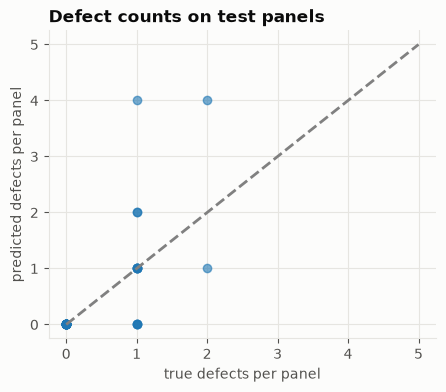

In [9]:
test = manifest[manifest["split"] == "test"].copy()
test["predicted"] = [len(detect.detect_defects(model, path)) for path in test["path"]]
test["defect_code"] = test["source"].str.split("_").str[1].where(test["has_defect"], "clean")

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(test["true_defects"], test["predicted"], alpha=0.6)
top = max(test["true_defects"].max(), test["predicted"].max()) + 1
ax.plot([0, top], [0, top], linestyle="--", color="gray")
ax.set_xlabel("true defects per panel"); ax.set_ylabel("predicted defects per panel")
ax.set_title("Defect counts on test panels")
save_figure(fig, "vision_02_counts")
plt.show()

In [10]:
# Which defect types are caught? (AITEX codes: 019 fuzzyball, 030 nep, 010 broken pick, 002 broken end, ...)
test[test["has_defect"]].assign(caught=lambda d: d["predicted"] > 0).groupby("defect_code").agg(
    panels=("caught", "size"), caught=("caught", "sum"))

,panels,caught
defect_code,,
002,1,1
006,3,2
010,2,2
019,6,5
023,3,1


## 6. Look at the mistakes

Missed defective panels: 4 | clean panels flagged: 0


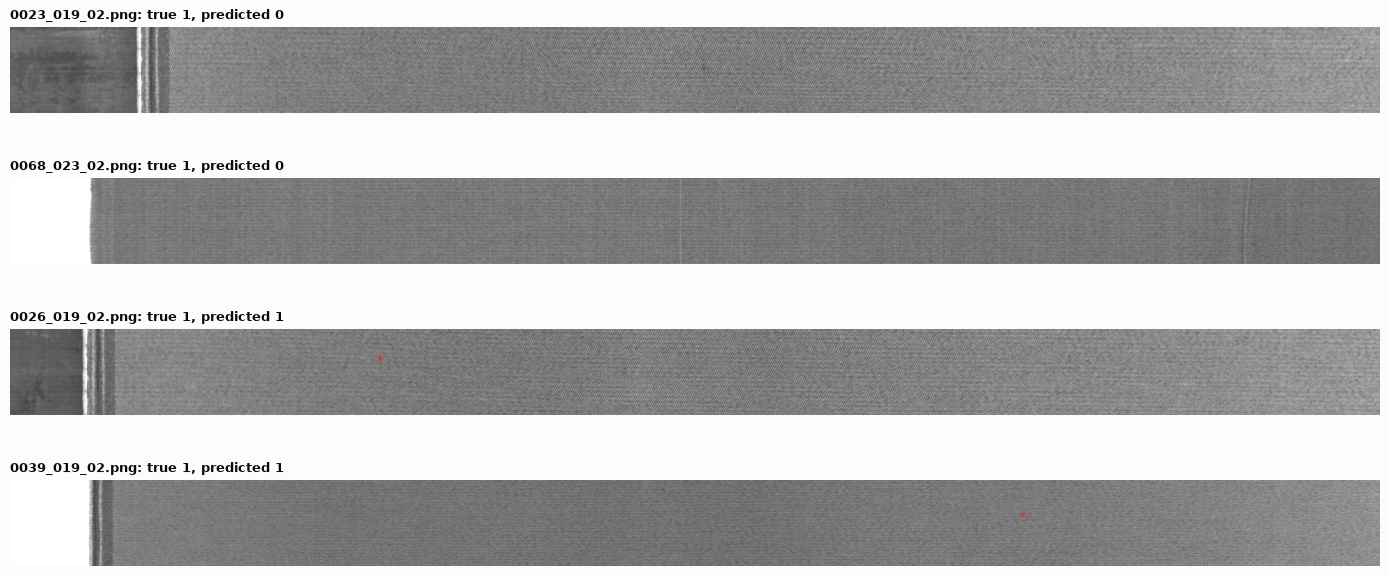

In [11]:
misses = test[test["has_defect"] & (test["predicted"] == 0)]
false_alarms = test[~test["has_defect"] & (test["predicted"] > 0)]
print(f"Missed defective panels: {len(misses)} | clean panels flagged: {len(false_alarms)}")

examples = pd.concat([misses.head(2), false_alarms.head(2), test[test["predicted"] > 0].head(2)])
fig, axes = plt.subplots(len(examples), 1, figsize=(14, 1.6 * len(examples)))
for ax, row in zip(np.atleast_1d(axes), examples.itertuples()):
    found = detect.detect_defects(model, row.path)
    ax.imshow(detect.draw_defects(row.path, found)); ax.axis("off")
    ax.set_title(f"{row.source}: true {row.true_defects}, predicted {len(found)}", fontsize=9)
plt.tight_layout()
save_figure(fig, "vision_03_examples")
plt.show()

## Summary

| Metric (36 held-out test panels, threshold 0.15) | Value |
|---|---|
| Defective panels caught | **11 of 15 (73%)** |
| Clean panels wrongly flagged | **0 of 21 (0%)** |
| Panel accuracy | **89%** |
| DHU: true vs predicted | **47.2 vs 52.8** |
| Tile precision / recall / mAP@50 | 0.71 / 0.36 / 0.35 |

**What works and what doesn't**
- Small, high-contrast defects are caught well: fuzzyballs (5 of 6), and every broken pick and broken end in the test set.
- Subtle, low-contrast defects are the weak spot: only 1 of 3 **creases** and 2 of 3 **broken yarn** panels are caught. They are faint lines that are hard to see even by eye.
- Tile-level recall (0.36) looks worse than panel-level results because a long defect spans many tiles: the panel is flagged as long as *some* part of it is found.

**Things to keep in mind**
- AITEX is small (104 usable defect images), so the test set holds only 15 defective panels; every panel moves a percentage by about 7 points.
- One defect can appear as several mask blobs, so "true defect" counts are approximate. Touching blobs are merged, as the detector does.
- For a factory, **missing a defect** usually costs more than a false alarm (a person re-checks flagged panels), so the threshold can be lowered on the Defect Scanner page when recall matters more.